In [1]:
# Name: Malolan Raghunathan Veeravalli
# Looking at a dataset on student well being in order to classify/predict depression.

In [2]:
# Pandas for handling data and passing it into the model for training.
# Matplotlib for visualizing model performance and metrics after training and testing and making predictions.
import pandas as pd
import matplotlib.pyplot as plt

In [21]:
# Importing the data as a pandas dataframe and removing a categorical column of data that 
# wouldn't be one hot encodable down the line.
# Data from https://www.kaggle.com/datasets/mkhoirulmustaqim/student-depression-detection-dataset?resource=download
df = pd.read_csv('Student_Depression_Dataset.csv')
df = df.drop(columns = 'Home_division')

In [4]:
# Features are all except the depression column because that is the target column
X = df.drop(columns = 'Depression')
# target column is the depression column, use the map function to one hot encode the nos to 0 and the yesses to 1. Added astype int to make sure the model takes in numerical data.
y = df['Depression'].map({'No' : 0, 'Yes' : 1}).astype(int)

In [5]:
# Splitting up which features are categorical and numerical in nature because within this dataset, the categorical
# features need to be one hot encoded. This means that we pass in a set of zeros (absence of the class) or ones (presence
# of the class) within that specific example (student). We also need to scale the numeric features because KNN works 
# based on some concept of distance (metric) depending on the dimension of the features.
categorical_features = [
    "Gender", "Family_background", "Relationship_status",
    "Marital_status", "Living_style", "friend_circle",
    "Health_condition"
]

numeric_features = [
    "Age", "Current_semester", "CGPA", "Cost_without_study"
]

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
# splitting the total observations into both training and testing data. Training to fit the model, test to asses performance.
# Stratify works by making sure that there is an approximately even amount of both classes of the target (depression)
# within both the training and test sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=10, shuffle = True, stratify=y, test_size=.2)

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [9]:
# First part of the pipeline that I intend to make, as I mentioned earlier, the numeric data needs to be scaled and the 
# categorical data needs to be encoded, within one hot encoder, drop first works to make sure that ther isn't a duplicate 
# column of the original class itself within the model, only the encoded columns now exist. 
preprocessing = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_features),
    ('categorical', OneHotEncoder(
        drop = 'first',
        handle_unknown='ignore', 
        sparse_output=False,
    ), categorical_features)
])

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

In [11]:
# planning on using a for loop to train both models and get all metrics/predictions at once to then visualize at the end.
# this dictionary is to use within the for loop as an iterator.
models = {
    'K Neighbors Classifier' : KNeighborsClassifier(n_neighbors=5),
    'Gaussian Naive Bayes' : GaussianNB()
}

In [12]:
from sklearn.model_selection import StratifiedKFold

In [13]:
# stratify preserves the proportion of classes within the depression target column. Using kfold to pass into cross validation 
# within the for loop for each model. 
kf = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=10
)

In [14]:
# Want to make sure we use recall, we do not want to miss a case of student depression

In [15]:
# allows me to process the data in a way that a model can learn from and then use the model itself in one action.
from sklearn.pipeline import make_pipeline
# allows me to make a copy of the original preprocessing object per model within the iterations of the for loop.
from sklearn.base import clone
# There are the metrics that I will use to judge model performance, recall is especially important because we do not want to
# miss a potential case of depression more than we are okay with incorrectly identifying someone as depressed.
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score
results = []
predictions = {}

In [16]:
# Implements all of the aforementioned steps
for name, classifier in models.items():
    # makes the model as a combination of the data preprocessing and the KNN or GaussNB itself
    model = make_pipeline(
        clone(preprocessing), clone(classifier)
    )
    # Calculates the cross validation score using ROC AUC, gives idea of how well a model predicts the positive and 
    # negative classes. .5 is as good as guessing, aiming for above that to show that model is better than guessing.
    cv_scores = cross_val_score(
        model, X_train, y_train, cv = kf, scoring = 'roc_auc'
    )

    # Fitting model to data to learn patterns and then predicting on the test set.
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Gathering all metrics and predictions to plot results of model performance
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0),
        "CV ROC-AUC mean": cv_scores.mean(),
        "CV ROC-AUC std": cv_scores.std()
    })

    predictions[name] = y_pred

In [17]:
# Converting the results list to a dataframe to see metrics
results_df = pd.DataFrame(results).set_index('Model')
results_df

,Accuracy,Precision,Recall,CV ROC-AUC mean,CV ROC-AUC std
Model,,,,,
K Neighbors Classifier,0.963046,0.972603,0.8875,0.982127,0.002673
Gaussian Naive Bayes,0.978723,0.995516,0.9250,0.986783,0.004757


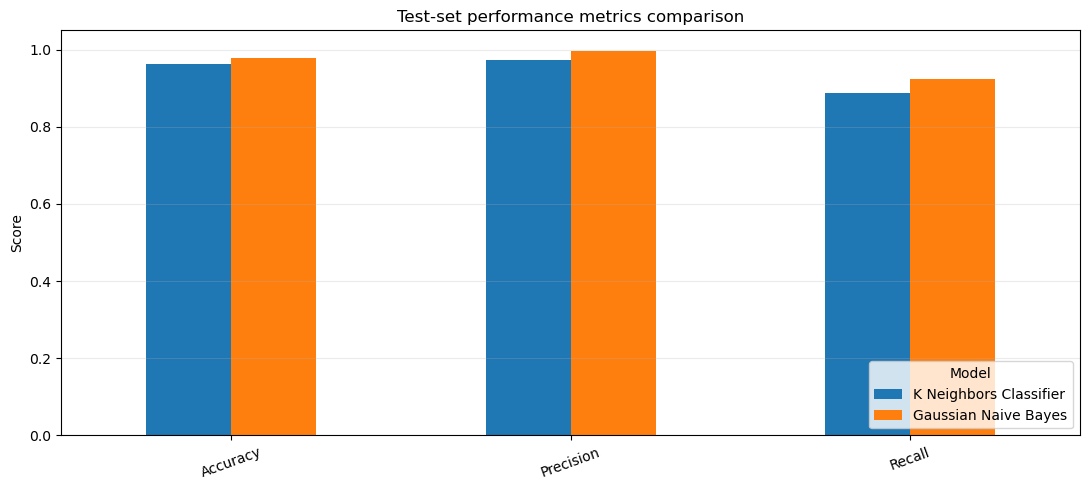

In [18]:
metric_columns = [
    "Accuracy", "Precision", "Recall",
]
# Transposing the results dataframe and using bar plots to make sure the metrics are on the x axis and then comparing both 
# KNN and GaussNB across acc, prec, recall
ax = results_df[metric_columns].T.plot.bar(
    figsize=(11, 5), rot=20
)
ax.set(
    title="Test-set performance metrics comparison",
    ylabel="Score",
    ylim=(0, 1.05)
)
ax.legend(title="Model", loc="lower right")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

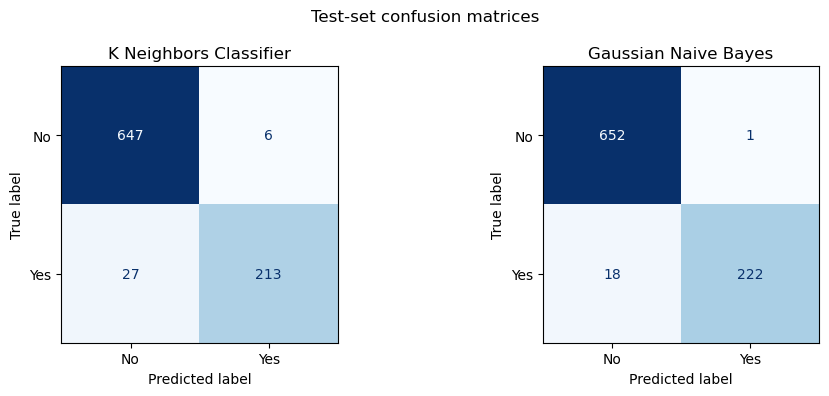

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
# Confusion matrix shows both 
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# Zip together the two axes and models, one confusion matrix for each model
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        # Using the y_test vs each specific model's predictions
        y_test,
        predictions[name],
        labels=[0, 1],
        display_labels=["No", "Yes"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(name)

fig.suptitle("Test-set confusion matrices")
plt.tight_layout()
plt.show()

In [ ]:
# Final Comments
# Mainly, when predicting the presence of depression, it is much more important that we do not miss a case of potential depression
# as opposed to incorrectly predicting someone to be depressed. This is why recall is crucial in this case. Both model's perform very
# well in general with around 96 to 98 percent accuracy. Gaussian NB does slightly better with a recall of 92.5%, but it also does better
# across all other metrics.
# If I was to add another layer to this project down the line, I would do some kind of grid search cv for the n_neighbors for
# KNN to see which model between 1 and maybe 50 does best. 